# Piecewise-linear surrogates for MILP embedding

This notebook walks through the workflow for building a tree surrogate that embeds exactly in a mixed-integer linear program:

1. **Affine leaves** (`leaf_type="affine"`): each leaf predicts $A_\ell x + b_\ell$. All outputs share one partition, and selected outputs can stay constant per leaf (`constant_outputs`).
2. **Jacobian matching**: when $\partial y/\partial x$ is available at the training points, `fit(X, y, dydx=J)` adds a Sobolev term that teaches the leaf slopes from fewer samples.
3. **Hardening**: anneal to crisp routing, freeze the partition, refit leaves by least squares, and report how much accuracy the soft model loses when routed crisply.
4. **Export**: leaf polytopes $\{x : G_\ell x \le h_\ell\}$ with their affine models in original units, with empty leaves pruned, plus the jax-ldt v1 JSON spec.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from difftree import DifferentiableTreeRegressor, export

## A two-output unit operation

Output 0 is piecewise linear with a kink along an oblique line. Output 1 is an intensive property that is constant on each side of the kink, which is the case where we want constant leaves so that bilinear blending terms linearize exactly. Inputs live on very different scales, to show that the export undoes the internal standardization.

In [2]:
def truth(X):
    u = X[:, 0] + 0.02 * X[:, 1] - 1.0           # oblique kink
    y0 = np.where(u > 0, 3.0 * u, -1.0 * u) + 0.01 * X[:, 1]   # continuous across the kink
    y1 = np.where(u > 0, 0.8, 0.2)
    return np.stack([y0, y1], axis=1)

def truth_jac(X):
    u = X[:, 0] + 0.02 * X[:, 1] - 1.0
    J = np.zeros((X.shape[0], 2, 2))
    right = u > 0
    J[:, 0, 0] = np.where(right, 3.0, -1.0)
    J[:, 0, 1] = np.where(right, 3.0 * 0.02, -1.0 * 0.02) + 0.01
    return J  # output 1 is piecewise constant: zero Jacobian

rng = np.random.default_rng(0)
lo, hi = np.array([0.0, -50.0]), np.array([2.0, 50.0])
X_te = rng.uniform(lo, hi, (4000, 2))
Y_te = truth(X_te)

## Affine vs constant leaves

60 training points. Everything below is hardened (`hardening=True`), so we compare the crisp models that would go into a MILP.

In [3]:
X = rng.uniform(lo, hi, (60, 2))
Y = truth(X) + 0.01 * rng.normal(size=(60, 2))
J = truth_jac(X)

common = dict(depth=2, n_epochs=300, batch_size=32, hardening=True, random_state=0)
models = {
    "constant": DifferentiableTreeRegressor(**common).fit(X, Y),
    "affine": DifferentiableTreeRegressor(leaf_type="affine", constant_outputs=[1], **common).fit(X, Y),
}
for name, mod in models.items():
    rmse = np.sqrt(np.mean((mod.predict(X_te, hard=True) - Y_te) ** 2, axis=0))
    print(f"{name:>9s}: hard RMSE y0={rmse[0]:.3f}  y1={rmse[1]:.3f}")

 constant: hard RMSE y0=0.762  y1=0.118
   affine: hard RMSE y0=0.023  y1=0.086


## Jacobian matching with very few samples

With 60 points the affine fit is already at the noise floor, so derivatives add little. They matter when samples are scarce. The cell below fits 5 random training sets each at $n = 12$ and $n = 24$, with and without `dydx`, and reports the median crisp RMSE on $y_0$. Individual runs vary, which is why we take the median.

In [4]:
rows = []
for n in (12, 24):
    errs = {"no dydx": [], "dydx": []}
    for seed in range(5):
        r = np.random.default_rng(100 + seed)
        Xn = r.uniform(lo, hi, (n, 2))
        Yn = truth(Xn) + 0.01 * r.normal(size=(n, 2))
        for name, dydx in (("no dydx", None), ("dydx", truth_jac(Xn))):
            mod = DifferentiableTreeRegressor(
                leaf_type="affine", constant_outputs=[1], validation_fraction=0.2, **common
            ).fit(Xn, Yn, dydx=dydx)
            errs[name].append(np.sqrt(np.mean((mod.predict(X_te, hard=True)[:, 0] - Y_te[:, 0]) ** 2)))
    print(f"n={n:2d}: median RMSE(y0) without dydx={np.median(errs['no dydx']):.3f}  "
          f"with dydx={np.median(errs['dydx']):.3f}")

n=12: median RMSE(y0) without dydx=0.106  with dydx=0.176


n=24: median RMSE(y0) without dydx=0.154  with dydx=0.153


On this problem the derivatives do not help: at $n = 12$ the median error is higher with `dydx`, and at $n = 24$ it is about the same. The remaining error comes from where the tree places the kink, and the Jacobian term informs that only indirectly. It trains the leaf slopes, while the splits move only through the routing weights. In the test suite there is a case where `dydx` clearly helps (30 samples, kink along $x_0 = 0$: crisp RMSE 0.41 → 0.17), so treat `jacobian_weight` as a hyperparameter and validate it on your data.

For the rest of the notebook we use the 60-point affine model, refit with the Jacobians.

In [5]:
m = DifferentiableTreeRegressor(leaf_type="affine", constant_outputs=[1], **common).fit(X, Y, dydx=J)

## The hardening report

`hardening_report_` compares soft and crisp predictions on the held-out validation slice, before and after hardening. A large `rmse_gap` (crisp minus soft) or a low `mean_max_leaf_prob` before hardening means the soft fit leans on blending leaves, which makes it a poor guide to the MILP model. `soft_hard_gap(X, y)` computes the same numbers on any data.

In [6]:
for stage in ("before", "after"):
    r = m.hardening_report_[stage]
    print(f"{stage:>6s}: rmse soft={np.round(r['rmse_soft'], 3)} hard={np.round(r['rmse_hard'], 3)} "
          f"gap={np.round(r['rmse_gap'], 3)}  max leaf prob={r['mean_max_leaf_prob']:.3f}")

gap = m.soft_hard_gap(X_te, Y_te)
print("test-set gap:", np.round(gap["rmse_gap"], 4), " routing agreement:", gap["routing_agreement"])

before: rmse soft=[0.009 0.009] hard=[0.009 0.009] gap=[-0. -0.]  max leaf prob=1.000
 after: rmse soft=[0.01  0.009] hard=[0.01  0.009] gap=[-0. -0.]  max leaf prob=1.000


test-set gap: [0.0021 0.0056]  routing agreement: 1.0


## Leaf polytopes in original units

`export.leaf_polytopes` returns one region per leaf, intersected with an input box (by default the training-data box; here we pass the design box). One LP per leaf drops leaves with an empty interior. A depth-2 tree has 4 leaves, but the box often contains only some of them.

In [7]:
polys = export.leaf_polytopes(m, bounds=(lo, hi), X=X)
print(f"{len(polys)} non-empty leaves of {2 ** m.depth}")
for lp in polys:
    print(f"leaf {lp.leaf}: n_train={lp.n_samples}, path={lp.path}")
    print("   coef =", np.round(lp.coef, 4).tolist(), " intercept =", np.round(lp.intercept, 4).tolist())

2 non-empty leaves of 4
leaf 2: n_train=39, path=[(0, 'right'), (2, 'left')]
   coef = [[-1.0019, -0.01], [0.0, -0.0]]  intercept = [0.9971, 0.2004]
leaf 3: n_train=21, path=[(0, 'right'), (2, 'right')]
   coef = [[2.9988, 0.07], [0.0, 0.0]]  intercept = [-2.9958, 0.8051]


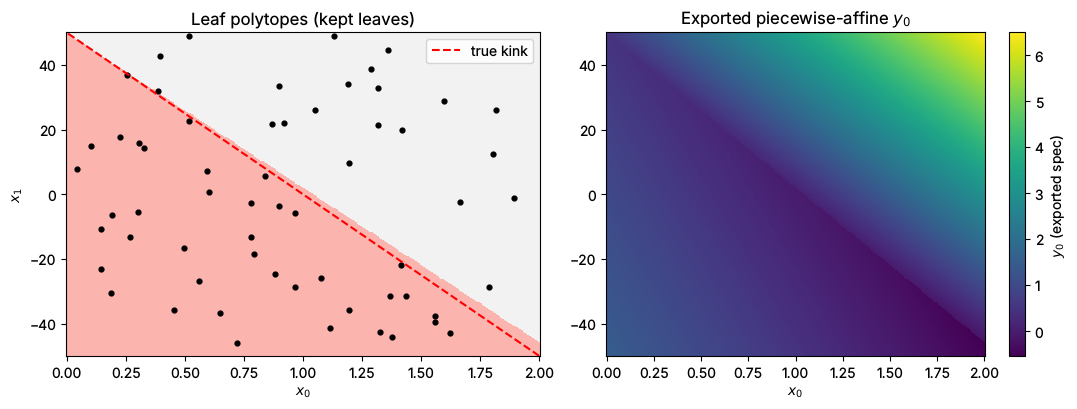

In [8]:
g0, g1 = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
G = np.stack([g0.ravel(), g1.ravel()], axis=1)
region = np.full(G.shape[0], -1)
for k, lp in enumerate(polys):
    region[lp.contains(G)] = k

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].pcolormesh(g0, g1, region.reshape(g0.shape), cmap="Pastel1", shading="auto")
axes[0].scatter(X[:, 0], X[:, 1], s=12, c="k")
u0 = np.linspace(lo[1], hi[1], 2)
axes[0].plot(1.0 - 0.02 * u0, u0, "r--", label="true kink")
axes[0].set(xlabel="$x_0$", ylabel="$x_1$", title="Leaf polytopes (kept leaves)")
axes[0].legend(loc="upper right")

pred = export.predict_spec(export.to_spec(m, bounds=(lo, hi)), G)[:, 0]
im = axes[1].pcolormesh(g0, g1, pred.reshape(g0.shape), shading="auto")
plt.colorbar(im, ax=axes[1], label="$y_0$ (exported spec)")
axes[1].set(xlabel="$x_0$", title="Exported piecewise-affine $y_0$")
plt.tight_layout()
plt.show()

## jax-ldt JSON spec

`export.to_json` writes the solver-neutral v1 spec of jax-ldt. Each oblique split is a lifted column of `transform_matrix` (`[I | a_1 ... a_k]`), so `jax_ldt.export.from_json` and its discopt adapter (`embed_in_discopt_model`) can consume the model directly. `export.predict_spec` evaluates a spec in NumPy and reproduces `predict(hard=True)` to round-off inside the box.

In [9]:
s = export.to_json(m, bounds=(lo, hi))
spec = json.loads(s)
print("kind:", spec["kind"], "| nodes:", spec["tree"]["node_count"],
      "| lifted features:", spec["n_features_transformed"])
X_box = rng.uniform(lo, hi, (2000, 2))
err = np.abs(export.predict_spec(spec, X_box) - m.predict(X_box, hard=True)).max()
print(f"max |spec - predict(hard=True)| = {err:.2e}")

kind: hyperplane_tree | nodes: 3 | lifted features: 3
max |spec - predict(hard=True)| = 1.78e-15


With jax-ldt (and discopt) installed, the same string embeds in a MILP:

```python
import jax; jax.config.update("jax_enable_x64", True)
import discopt
from jax_ldt import from_json
from jax_ldt.export import embed_in_discopt_model

tree = from_json(s)
mdl = discopt.Model("surrogate")
x = mdl.continuous("x", shape=(2,), lb=lo, ub=hi)
y = embed_in_discopt_model(tree, mdl, x)
mdl.minimize(y[0])
result = mdl.solve()
```

The MILP treats leaf polytopes as closed sets, so an optimum can sit on a split boundary and use either neighbouring leaf's model there. See jax-ldt's `boundary_eps` option if that matters.

## Split boundaries: jumps and repairing a MILP solution

A crisp piecewise-affine tree can jump across a split. The MILP treats leaf polytopes as closed, so its optimum can land on a boundary and use either neighbouring leaf's model, while `predict(hard=True)` sends boundary points left. `export.boundary_jumps` measures how large the jumps are on every shared facet in the box.

In [10]:
for j in export.boundary_jumps(m, bounds=(lo, hi)):
    print(f"node {j['node']}: leaves {j['left']}|{j['right']}  max jump per output = {np.round(j['max_jump'], 3)}")

node 2: leaves 2|3  max jump per output = [0.348 0.605]


Suppose a MILP returns a point on this boundary where the jump is largest. At a boundary point the solver can report either neighbouring leaf, and its objective uses that leaf's model (in practice, read the chosen leaf from the binaries with `export.leaf_from_binaries(spec, z)`). Below we take the leaf that `predict(hard=True)` does *not* use at that exact point, which is the case that causes trouble. `export.repair_solution` moves the point $\delta$ (standardized units) into the chosen leaf, after which crisp prediction and the MILP agree.

In [11]:
j = export.boundary_jumps(m, bounds=(lo, hi))[0]
x_boundary = j["worst_point"][0]   # where output 0 jumps the most
polys = {lp.leaf: lp for lp in export.leaf_polytopes(m, bounds=(lo, hi))}
vals = {leaf: polys[leaf].predict(x_boundary[None])[0, 0] for leaf in (j["left"], j["right"])}
routed = m.apply(x_boundary[None])[0]
chosen = j["right"] if routed == j["left"] else j["left"]   # the solver's choice
x_fixed = export.repair_solution(m, x_boundary, chosen, bounds=(lo, hi))
print(f"MILP objective (leaf {chosen})       : {vals[chosen]:.4f}")
print(f"predict(hard=True) at boundary  : {m.predict(x_boundary[None], hard=True)[0, 0]:.4f}  (leaf {m.apply(x_boundary[None])[0]})")
print(f"predict(hard=True) after repair : {m.predict(x_fixed[None], hard=True)[0, 0]:.4f}  (leaf {m.apply(x_fixed[None])[0]})")
print(f"moved by {np.max(np.abs((x_fixed - x_boundary) / m.x_std_)):.1e} (standardized units)")

MILP objective (leaf 3)       : -0.2009
predict(hard=True) at boundary  : -0.5486  (leaf 2)
predict(hard=True) after repair : -0.2009  (leaf 3)
moved by 2.2e-06 (standardized units)


## Jumps vs continuity

There are three ways to harden the same data:

- **discontinuous** (default): every leaf is fitted on its own, so neighbouring leaves can disagree at a split.
- **continuous, untied** (`continuous=True`): neighbouring leaves must agree on each shared facet. On an oblique tree this is expensive. Wherever a deeper split meets a parent boundary (a T-junction), both leaves of that split must match the same neighbour, which forces them to merge unless the two hyperplanes coincide. Each kink is also pinned to wherever the learned split happens to sit.
- **continuous, tied** (`tied_splits=True, continuous=True`): all nodes at a depth share one hyperplane, so every junction is a crossing. A continuous function on that partition is exactly a hinging-hyperplanes model, $\theta_0 \cdot [1, x] + \sum_d c_d \max(0, w_d \cdot x + b_d)$, which hardening fits directly while moving the hyperplanes to reduce the error (`refine_splits`). It is continuous everywhere, not only inside the box.

The first panel takes a slice through the oblique kink of this notebook's function. The second uses a 3-input function with two kinks, $|x_0| + x_1 + \max(x_2, 0)$, sliced along $x_0$.

In [12]:
variants = {
    "discontinuous": dict(),
    "continuous, untied": dict(continuous=True),
    "continuous, tied": dict(continuous=True, tied_splits=True),
}
aff = dict(leaf_type="affine", constant_outputs=[1], **common)
fits2d = {name: DifferentiableTreeRegressor(**aff, **kw).fit(X, Y) for name, kw in variants.items()}

f3 = lambda Z: np.abs(Z[:, 0]) + Z[:, 1] + np.maximum(Z[:, 2], 0)
r3 = np.random.default_rng(1)
X3 = r3.uniform(-2, 2, (600, 3))
y3 = f3(X3) + 0.02 * r3.normal(size=600)
X3_te = r3.uniform(-2, 2, (5000, 3))
kw3 = dict(depth=3, n_epochs=80, leaf_type="affine", hardening=True, n_hard_epochs=20, random_state=0)
fits3d = {name: DifferentiableTreeRegressor(**kw3, **kw).fit(X3, y3) for name, kw in variants.items()}

print(f"{'':>20s} {'2-D kink (y0)':>24s}   {'3-D two kinks':>24s}")
print(f"{'':>20s} {'RMSE':>10s} {'max jump':>12s}   {'RMSE':>10s} {'max jump':>12s}")
for name in variants:
    a, b = fits2d[name], fits3d[name]
    ra = np.sqrt(np.mean((a.predict(X_te, hard=True)[:, 0] - Y_te[:, 0]) ** 2))
    rb = np.sqrt(np.mean((b.predict(X3_te, hard=True) - f3(X3_te)) ** 2))
    print(f"{name:>20s} {ra:10.3f} {a.hardening_report_['max_boundary_jump'][0]:12.2e}   "
          f"{rb:10.3f} {b.hardening_report_['max_boundary_jump'][0]:12.2e}")

                                2-D kink (y0)              3-D two kinks
                           RMSE     max jump         RMSE     max jump
       discontinuous      0.023     3.58e-01        0.049     3.60e-01
  continuous, untied      0.073     8.07e-16        0.583     2.54e-15
    continuous, tied      0.009     9.41e-16        0.004     3.94e-16


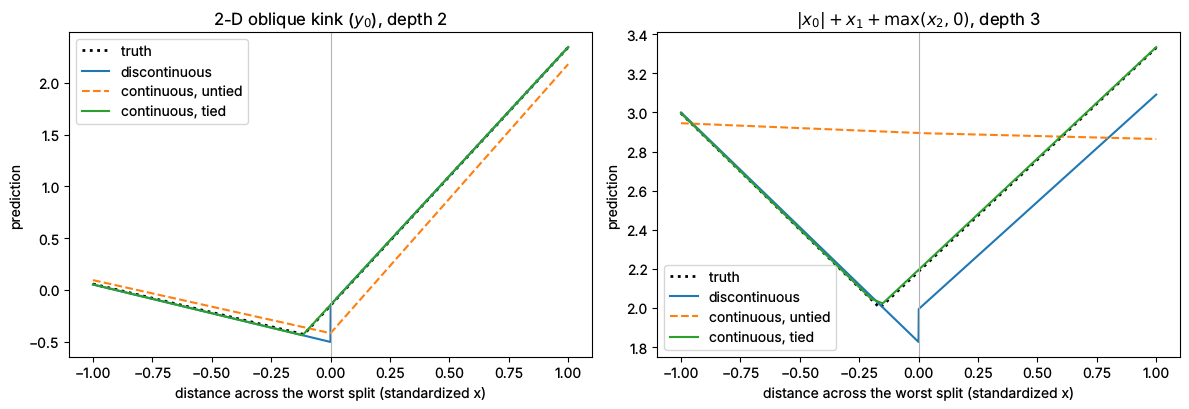

In [13]:
styles = {"discontinuous": ("C0", "-"), "continuous, untied": ("C1", "--"), "continuous, tied": ("C2", "-")}

def worst_slice(model, half_width=1.0, n=2000):
    """Line through the discontinuous model's worst jump, across that split.
    Returns (t, points): t is the signed distance in standardized x units."""
    j = export.boundary_jumps(model)[0]
    x_w = j["worst_point"][0]
    w = model.params_["W"][j["node"]]
    step = (w / np.linalg.norm(w)) * model.x_std_   # unit step in standardized units
    t = np.linspace(-half_width, half_width, n)
    return t, x_w[None, :] + t[:, None] * step[None, :]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, fits, f_true, title in (
    (axes[0], fits2d, lambda Z: truth(Z)[:, 0], "2-D oblique kink ($y_0$), depth 2"),
    (axes[1], fits3d, f3, "$|x_0| + x_1 + \\max(x_2, 0)$, depth 3"),
):
    t, S = worst_slice(fits["discontinuous"])
    ax.plot(t, f_true(S), "k:", lw=2, label="truth")
    for name, mod in fits.items():
        c, ls = styles[name]
        pred = mod.predict(S, hard=True)
        ax.plot(t, pred[:, 0] if pred.ndim == 2 else pred, color=c, ls=ls, label=name)
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set(xlabel="distance across the worst split (standardized x)", ylabel="prediction", title=title)
    ax.legend()
plt.tight_layout()
plt.show()

Each slice crosses the split where the discontinuous tree's jump is largest (the grey line). There the blue curve steps, which is the jump a MILP can exploit. The green curve crosses smoothly and follows the truth. The orange curve is continuous but has lost most of the shape.

On these problems the tied continuous model has no jumps and is at least as accurate as the discontinuous tree. The untied continuous model is jump-free but much less accurate, for the reasons above. Tied splits do restrict the partition (one hyperplane per depth). On smooth functions with no kink structure (e.g. $\sin 2x$ or a Gaussian bump) the README's comparison shows the tied continuous model roughly matching the discontinuous tree, sometimes slightly worse, so check `soft_hard_gap` and `boundary_jumps` on your own data.